# VS code cũng đẹp mà
Tui yêu cái đẹp, thấy cái gì đẹp là tui lưu lại hết à
Tui muốn sản phẩm mk làm ra có sự chỉnh chu, áp dụng được vào thực tiễn, thực sự có ích cho đời

In [2]:
# import libraries 

import numpy as np
import pandas as pd
import unicodedata
import re


#Vẽ biểu đồ
import matplotlib.pyplot as plt 

# Vẽ biểu đồ nhiệt
import seaborn as sns

from collections import Counter

# 1. ETL Basic Statisctic

In [3]:
# review file data
filename = r"E:\Chuyển từ download sang\A Học tập Bách Khoa\ĐA2\Đồ án 2 _ 2025\Project_full\Crawl_job\Data_raw\data_vietnamworks.csv"

df=pd.read_csv(filename)
df

,index,job_link,keyword,title,company,location,salary,date_posted,deadline_date,category,...,job_level,experience,education,hire_number,age,skills,is_urgent,description,requirements,benefits
0,1,https://www.vietnamworks.com/kiem-toan-vien-ki...,Data Analyst,Kiểm Toán Viên / Kiểm Toán Nội Bộ,Ngân Hàng Thương Mại TNHH MTV Ngoại Thương Côn...,Hà Nội,Thương lượng,27/03/2026,2026-04-26,Kiểm Toán,...,Nhân viên,3,Cử nhân,2,Không hiển thị,"Audit, Kiểm Toán, Kiểm Toán Viên Cao Cấp, Phân...",No,MÔ TẢ CÔNG VIỆC 1. Thực hiện công việc thuộc c...,Trình độ chuyên môn: Tốt nghiệp đại học chính ...,Đào tạo|Khác
1,2,https://www.vietnamworks.com/ky-su-phat-trien-...,Data Analyst,"Kỹ Sư Phát Triển Nền Tảng, Hệ Thống","Viện Phát Triển Chuyển Đổi Xanh, Chuyển Đổi Số...",Hà Nội,Thương lượng,27/03/2026,2026-04-26,Data Engineer/Data Analyst/AI,...,Nhân viên,Không hiển thị,Không giới hạn,Không hiển thị,Không hiển thị,"AI, Khoa Học Máy Tính, Kỹ Thuật Phần Mềm",No,"1) Tham gia thiết kế kiến trúc, phát triển chứ...","1) Tốt nghiệp đại học trở lên, chuyên ngành Kh...",Thưởng|Chăm sóc sức khoẻ
2,3,https://www.vietnamworks.com/chuyen-vien-cao-c...,Data Analyst,Chuyên Viên Cao Cấp Vận Hành Thương Hiệu Quốc Tế,Trang Văn hóa công ty,Hồ Chí Minh,Thương lượng,27/03/2026,2026-04-26,Tiếp Thị,...,Nhân viên,3,Cử nhân,Không hiển thị,Không hiển thị,"Quản Trị Hàng Hóa, Phân tích dữ liệu, Truyền t...",No,"Mục đích vị trí công việc Triển khai, theo dõi...",1. Bằng cấp: Đại học Chuyên ngành: QTKD/Market...,Thưởng|Chăm sóc sức khoẻ|Nghỉ phép có lương
3,4,https://www.vietnamworks.com/nhan-vien-phat-tr...,Data Analyst,Nhân Viên Phát Triển Dự Án Nông Nghiệp (Agricu...,CÔNG TY TNHH MUYUAN VIỆT NAM,Hồ Chí Minh,16tr-30tr ₫/tháng,27/03/2026,2026-04-26,Nông/Lâm/Ngư nghiệp,...,Nhân viên,1,Cao đẳng,Không hiển thị,23-35,"Giao Tiếp Đàm Phán, Nghiên Cứu Môi Trường, Ngh...",No,Mô tả công việc: 1. Quan hệ chính phủ & kết nố...,Tốt nghiệp cao đẳng trở lên (ưu tiên ngành nôn...,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác
4,5,https://www.vietnamworks.com/ie-engineer-20310...,Data Analyst,IE Engineer,CÔNG TY TNHH DỆT REGENT VIỆT NAM,Phú Thọ,Thương lượng,27/03/2026,2026-04-26,Thiết Kế Công Nghiệp/Kỹ Thuật,...,Nhân viên,2,Cử nhân,1,Không hiển thị,"Data Analysis, Industrial Engineering, Analysi...",No,POSITION SUMMARY We are recruiting an IE engin...,"KNOWLEDGE, SKILLS AND ABILITIES Bachelor's Deg...",Thưởng|Đào tạo|Khác
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2401,2402,https://www.vietnamworks.com/senior-supply-cha...,Business Intelligence,Senior Supply Chain Operation Executive,CÔNG TY TNHH BLUEZON GLOBAL,Hồ Chí Minh,25tr-35tr ₫/tháng,08/06/2026,2026-07-08,Quản Lý Chuỗi Cung Ứng,...,Nhân viên,2,Cử nhân,Không hiển thị,Không hiển thị,"Supply Chain Management, Logistics operations,...",No,1. Supply Planning & Inventory Monitoring Rece...,'- Education: Bachelor’s degree in Supply Chai...,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác
2402,2403,https://www.vietnamworks.com/business-analyst-...,Business Intelligence,Business Analyst,CÔNG TY TNHH EZ TECH VIỆT NAM,Hà Nội,Thương lượng,08/06/2026,2026-07-08,Phân Tích Kinh Doanh/Phân Tích Hệ Thống,...,Nhân viên,2,Không giới hạn,1,Không hiển thị,"Phân tích nghiệp vụ, Tư duy logic, Tư Duy Hệ T...",No,"Làm việc với các bên liên quan để thu thập, ph...",Có tối thiểu 02 năm kinh nghiệm ở vị trí Busin...,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác
2403,2404,https://www.vietnamworks.com/giam-doc-kinh-doa...,Business Intelligence,Giám Đốc Kinh Doanh | Sales Director | Thu Nhậ...,Công Ty CP Tập Đoàn Vinatech Việt Nam,Hà Nội,"$ 1,500-2,500 /tháng",08/06/2026,2026-07-08,Phân Tích Kinh Doanh/Phân Tích Hệ Thống,...,Giám Đốc và Cấp Cao Hơn,10,Cử nhân,Không hiển thị,37-50,"Sales & Business Development, Giám đốc kinh do...",No,1. Mục tiêu công việc: Chịu trách nhiệm xây dự...,Kinh nghiệm Tối thiểu 8 – 10 năm kinh nghiệm t...,Thưởng|Nghỉ phép có lương|Khác
2404,2405,https://www.vietnamworks.com/campaign-manageme...,Business Intelligence,Campai

## 1. ĐỔI TÊN CỘT

### 1.1 Thêm cột "source" cho data, mặc định `1` nghĩa là `vietnamworks`

In [4]:
df['source'] = "1"

In [5]:
df.head(10)

,index,job_link,keyword,title,company,location,salary,date_posted,deadline_date,category,...,experience,education,hire_number,age,skills,is_urgent,description,requirements,benefits,source
0,1,https://www.vietnamworks.com/kiem-toan-vien-ki...,Data Analyst,Kiểm Toán Viên / Kiểm Toán Nội Bộ,Ngân Hàng Thương Mại TNHH MTV Ngoại Thương Côn...,Hà Nội,Thương lượng,27/03/2026,2026-04-26,Kiểm Toán,...,3,Cử nhân,2,Không hiển thị,"Audit, Kiểm Toán, Kiểm Toán Viên Cao Cấp, Phân...",No,MÔ TẢ CÔNG VIỆC 1. Thực hiện công việc thuộc c...,Trình độ chuyên môn: Tốt nghiệp đại học chính ...,Đào tạo|Khác,1
1,2,https://www.vietnamworks.com/ky-su-phat-trien-...,Data Analyst,"Kỹ Sư Phát Triển Nền Tảng, Hệ Thống","Viện Phát Triển Chuyển Đổi Xanh, Chuyển Đổi Số...",Hà Nội,Thương lượng,27/03/2026,2026-04-26,Data Engineer/Data Analyst/AI,...,Không hiển thị,Không giới hạn,Không hiển thị,Không hiển thị,"AI, Khoa Học Máy Tính, Kỹ Thuật Phần Mềm",No,"1) Tham gia thiết kế kiến trúc, phát triển chứ...","1) Tốt nghiệp đại học trở lên, chuyên ngành Kh...",Thưởng|Chăm sóc sức khoẻ,1
2,3,https://www.vietnamworks.com/chuyen-vien-cao-c...,Data Analyst,Chuyên Viên Cao Cấp Vận Hành Thương Hiệu Quốc Tế,Trang Văn hóa công ty,Hồ Chí Minh,Thương lượng,27/03/2026,2026-04-26,Tiếp Thị,...,3,Cử nhân,Không hiển thị,Không hiển thị,"Quản Trị Hàng Hóa, Phân tích dữ liệu, Truyền t...",No,"Mục đích vị trí công việc Triển khai, theo dõi...",1. Bằng cấp: Đại học Chuyên ngành: QTKD/Market...,Thưởng|Chăm sóc sức khoẻ|Nghỉ phép có lương,1
3,4,https://www.vietnamworks.com/nhan-vien-phat-tr...,Data Analyst,Nhân Viên Phát Triển Dự Án Nông Nghiệp (Agricu...,CÔNG TY TNHH MUYUAN VIỆT NAM,Hồ Chí Minh,16tr-30tr ₫/tháng,27/03/2026,2026-04-26,Nông/Lâm/Ngư nghiệp,...,1,Cao đẳng,Không hiển thị,23-35,"Giao Tiếp Đàm Phán, Nghiên Cứu Môi Trường, Ngh...",No,Mô tả công việc: 1. Quan hệ chính phủ & kết nố...,Tốt nghiệp cao đẳng trở lên (ưu tiên ngành nôn...,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác,1
4,5,https://www.vietnamworks.com/ie-engineer-20310...,Data Analyst,IE Engineer,CÔNG TY TNHH DỆT REGENT VIỆT NAM,Phú Thọ,Thương lượng,27/03/2026,2026-04-26,Thiết Kế Công Nghiệp/Kỹ Thuật,...,2,Cử nhân,1,Không hiển thị,"Data Analysis, Industrial Engineering, Analysi...",No,POSITION SUMMARY We are recruiting an IE engin...,"KNOWLEDGE, SKILLS AND ABILITIES Bachelor's Deg...",Thưởng|Đào tạo|Khác,1
5,6,https://www.vietnamworks.com/solar-project-dev...,Data Analyst,Solar Project Development Specialist (Chuyên V...,CÔNG TY CỔ PHẦN TẬP ĐOÀN DAT,"Hồ Chí Minh, Hà Nội","$ 1,145-1,526 /tháng",27/03/2026,2026-04-26,Bán Hàng Kỹ Thuật,...,3,Cử nhân,1,24-35,"Communication, Data Analysis, Project Manageme...",No,"'- Chủ động tìm kiếm, trực tiếp tiếp cận khách...",'- Tốt nghiệp Cao đẳng trở lên các ngành Quản ...,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác,1
6,7,https://www.vietnamworks.com/head-of-sourcing-...,Data Analyst,Head of Sourcing,Yes4All Trading Services Company Limited,Hồ Chí Minh,Thương lượng,27/03/2026,2026-04-26,Quản Lý Chuỗi Cung Ứng,...,5,Cử nhân,1,Không hiển thị,"Data Analysis, Merchandising, Project Manageme...",No,JOB PURPOSE The Head of Sourcing at Yes4All is...,Education ● Bachelor’s degree in business admi...,Khác,1
7,8,https://www.vietnamworks.com/digital-content-m...,Data Analyst,Digital & Content Manager – Thu Nhập Up to 45M,Công ty TNHHH ĐT XNK Hoan TT,Hà Nội,25tr-45tr ₫/tháng,27/03/2026,2026-04-26,Tiếp Thị Trực Tuyến,...,3,Không giới hạn,Không hiển thị,Không hiển thị,"Digital Marketing, Data Analysis, Content Stra...",No,1. Mục đích công việc (Job Purpose) Xây dựng v...,Kinh nghiệm: Tối thiểu 3 năm ở vị trí tương đư...,Thưởng|Nghỉ phép có lương|Đào tạo|Khác,1
8,9,https://www.vietnamworks.com/nhan-vien-ke-hoac...,Data Analyst,Nhân Viên Kế Hoạch Sản Xuất (Production Planni...,CÔNG TY TNHH TRÀ VÀ ĐẶC SẢN TÂY BẮC,Hà Nội,Thương lượng,27/03/2026,2026-04-26,Hoạch Định & Quản Lý Sản Xuất,...,3,Cử nhân,Không hiển thị,Không hiển thị,"Kế Hoạch Sản Xuất, Phân tích dữ liệu, Producti...",No,1. Lập kế hoạch sản xuất Lập kế ho

### 1.2 Đổi tên 1 loạt các cột khác

In [6]:
df = df.rename(columns={
    'job_link': 'job_url',
    'title': 'job_title',
    'field': 'company_field',
    'skills': 'job_skills'
})

In [10]:
df.head(10)

,index,job_url,keyword,job_title,company,location,salary,date_posted,deadline_date,category,...,experience,education,hire_number,age,job_skills,is_urgent,description,requirements,benefits,source
0,1,https://www.vietnamworks.com/kiem-toan-vien-ki...,Data Analyst,Kiểm Toán Viên / Kiểm Toán Nội Bộ,Ngân Hàng Thương Mại TNHH MTV Ngoại Thương Côn...,Hà Nội,Thương lượng,27/03/2026,2026-04-26,Kiểm Toán,...,3,Cử nhân,2,Không hiển thị,"Audit, Kiểm Toán, Kiểm Toán Viên Cao Cấp, Phân...",No,MÔ TẢ CÔNG VIỆC 1. Thực hiện công việc thuộc c...,Trình độ chuyên môn: Tốt nghiệp đại học chính ...,Đào tạo|Khác,1
1,2,https://www.vietnamworks.com/ky-su-phat-trien-...,Data Analyst,"Kỹ Sư Phát Triển Nền Tảng, Hệ Thống","Viện Phát Triển Chuyển Đổi Xanh, Chuyển Đổi Số...",Hà Nội,Thương lượng,27/03/2026,2026-04-26,Data Engineer/Data Analyst/AI,...,Không hiển thị,Không giới hạn,Không hiển thị,Không hiển thị,"AI, Khoa Học Máy Tính, Kỹ Thuật Phần Mềm",No,"1) Tham gia thiết kế kiến trúc, phát triển chứ...","1) Tốt nghiệp đại học trở lên, chuyên ngành Kh...",Thưởng|Chăm sóc sức khoẻ,1
2,3,https://www.vietnamworks.com/chuyen-vien-cao-c...,Data Analyst,Chuyên Viên Cao Cấp Vận Hành Thương Hiệu Quốc Tế,Trang Văn hóa công ty,Hồ Chí Minh,Thương lượng,27/03/2026,2026-04-26,Tiếp Thị,...,3,Cử nhân,Không hiển thị,Không hiển thị,"Quản Trị Hàng Hóa, Phân tích dữ liệu, Truyền t...",No,"Mục đích vị trí công việc Triển khai, theo dõi...",1. Bằng cấp: Đại học Chuyên ngành: QTKD/Market...,Thưởng|Chăm sóc sức khoẻ|Nghỉ phép có lương,1
3,4,https://www.vietnamworks.com/nhan-vien-phat-tr...,Data Analyst,Nhân Viên Phát Triển Dự Án Nông Nghiệp (Agricu...,CÔNG TY TNHH MUYUAN VIỆT NAM,Hồ Chí Minh,16tr-30tr ₫/tháng,27/03/2026,2026-04-26,Nông/Lâm/Ngư nghiệp,...,1,Cao đẳng,Không hiển thị,23-35,"Giao Tiếp Đàm Phán, Nghiên Cứu Môi Trường, Ngh...",No,Mô tả công việc: 1. Quan hệ chính phủ & kết nố...,Tốt nghiệp cao đẳng trở lên (ưu tiên ngành nôn...,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác,1
4,5,https://www.vietnamworks.com/ie-engineer-20310...,Data Analyst,IE Engineer,CÔNG TY TNHH DỆT REGENT VIỆT NAM,Phú Thọ,Thương lượng,27/03/2026,2026-04-26,Thiết Kế Công Nghiệp/Kỹ Thuật,...,2,Cử nhân,1,Không hiển thị,"Data Analysis, Industrial Engineering, Analysi...",No,POSITION SUMMARY We are recruiting an IE engin...,"KNOWLEDGE, SKILLS AND ABILITIES Bachelor's Deg...",Thưởng|Đào tạo|Khác,1
5,6,https://www.vietnamworks.com/solar-project-dev...,Data Analyst,Solar Project Development Specialist (Chuyên V...,CÔNG TY CỔ PHẦN TẬP ĐOÀN DAT,"Hồ Chí Minh, Hà Nội","$ 1,145-1,526 /tháng",27/03/2026,2026-04-26,Bán Hàng Kỹ Thuật,...,3,Cử nhân,1,24-35,"Communication, Data Analysis, Project Manageme...",No,"'- Chủ động tìm kiếm, trực tiếp tiếp cận khách...",'- Tốt nghiệp Cao đẳng trở lên các ngành Quản ...,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác,1
6,7,https://www.vietnamworks.com/head-of-sourcing-...,Data Analyst,Head of Sourcing,Yes4All Trading Services Company Limited,Hồ Chí Minh,Thương lượng,27/03/2026,2026-04-26,Quản Lý Chuỗi Cung Ứng,...,5,Cử nhân,1,Không hiển thị,"Data Analysis, Merchandising, Project Manageme...",No,JOB PURPOSE The Head of Sourcing at Yes4All is...,Education ● Bachelor’s degree in business admi...,Khác,1
7,8,https://www.vietnamworks.com/digital-content-m...,Data Analyst,Digital & Content Manager – Thu Nhập Up to 45M,Công ty TNHHH ĐT XNK Hoan TT,Hà Nội,25tr-45tr ₫/tháng,27/03/2026,2026-04-26,Tiếp Thị Trực Tuyến,...,3,Không giới hạn,Không hiển thị,Không hiển thị,"Digital Marketing, Data Analysis, Content Stra...",No,1. Mục đích công việc (Job Purpose) Xây dựng v...,Kinh nghiệm: Tối thiểu 3 năm ở vị trí tương đư...,Thưởng|Nghỉ phép có lương|Đào tạo|Khác,1
8,9,https://www.vietnamworks.com/nhan-vien-ke-hoac...,Data Analyst,Nhân Viên Kế Hoạch Sản Xuất (Production Planni...,CÔNG TY TNHH TRÀ VÀ ĐẶC SẢN TÂY BẮC,Hà Nội,Thương lượng,27/03/2026,2026-04-26,Hoạch Định & Quản Lý Sản Xuất,...,3,Cử nhân,Không hiển thị,Không hiển thị,"Kế Hoạch Sản Xuất, Phân tích dữ liệu, Producti...",No,1. Lập kế hoạch sản xuất Lậ

In [ ]:
## 2. SAVED lần 1
df.to_csv("data_vnw_1.csv", index=False, encoding="utf-8-sig")

### 1.3 Đổi tên sau khi ETL hàng loạt + chuẩn bị ghép file

In [3]:
# review file data
filename_4 = r"data_vnw_4.csv"

df=pd.read_csv(filename_4)
df.head(5)

,index,job_url,keyword,job_title,company,location,salary,date_posted,deadline_date,category,...,job_skills,is_urgent,description,requirements,benefits,source,work_type,job_position,edu,mean_salary
0,1,https://www.vietnamworks.com/kiem-toan-vien-ki...,Data Analyst,Kiểm Toán Viên / Kiểm Toán Nội Bộ,Ngân Hàng Thương Mại TNHH MTV Ngoại Thương Côn...,Hà Nội,Thương lượng,2026-03-27,2026-04-26,Kiểm Toán,...,"Audit, Kiểm Toán, Kiểm Toán Viên Cao Cấp, Phân...",No,MÔ TẢ CÔNG VIỆC 1. Thực hiện công việc thuộc c...,Trình độ chuyên môn: Tốt nghiệp đại học chính ...,Đào tạo|Khác,1,Full-time,Nhân viên,Đại học,NaN
1,2,https://www.vietnamworks.com/ky-su-phat-trien-...,Data Analyst,"Kỹ Sư Phát Triển Nền Tảng, Hệ Thống","Viện Phát Triển Chuyển Đổi Xanh, Chuyển Đổi Số...",Hà Nội,Thương lượng,2026-03-27,2026-04-26,Data Engineer/Data Analyst/AI,...,"AI, Khoa Học Máy Tính, Kỹ Thuật Phần Mềm",No,"1) Tham gia thiết kế kiến trúc, phát triển chứ...","1) Tốt nghiệp đại học trở lên, chuyên ngành Kh...",Thưởng|Chăm sóc sức khoẻ,1,Full-time,Nhân viên,Ko yêu cầu,NaN
2,3,https://www.vietnamworks.com/chuyen-vien-cao-c...,Data Analyst,Chuyên Viên Cao Cấp Vận Hành Thương Hiệu Quốc Tế,Trang Văn hóa công ty,Hồ Chí Minh,Thương lượng,2026-03-27,2026-04-26,Tiếp Thị,...,"Quản Trị Hàng Hóa, Phân tích dữ liệu, Truyền t...",No,"Mục đích vị trí công việc Triển khai, theo dõi...",1. Bằng cấp: Đại học Chuyên ngành: QTKD/Market...,Thưởng|Chăm sóc sức khoẻ|Nghỉ phép có lương,1,Full-time,Nhân viên,Đại học,NaN
3,4,https://www.vietnamworks.com/nhan-vien-phat-tr...,Data Analyst,Nhân Viên Phát Triển Dự Án Nông Nghiệp (Agricu...,CÔNG TY TNHH MUYUAN VIỆT NAM,Hồ Chí Minh,16tr-30tr ₫/tháng,2026-03-27,2026-04-26,Nông/Lâm/Ngư nghiệp,...,"Giao Tiếp Đàm Phán, Nghiên Cứu Môi Trường, Ngh...",No,Mô tả công việc: 1. Quan hệ chính phủ & kết nố...,Tốt nghiệp cao đẳng trở lên (ưu tiên ngành nôn...,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác,1,Full-time,Nhân viên,Cao đẳng,23000000.0
4,5,https://www.vietnamworks.com/ie-engineer-20310...,Data Analyst,IE Engineer,CÔNG TY TNHH DỆT REGENT VIỆT NAM,Phú Thọ,Thương lượng,2026-03-27,2026-04-26,Thiết Kế Công Nghiệp/Kỹ Thuật,...,"Data Analysis, Industrial Engineering, Analysi...",No,POSITION SUMMARY We are recruiting an IE engin...,"KNOWLEDGE, SKILLS AND ABILITIES Bachelor's Deg...",Thưởng|Đào tạo|Khác,1,Full-time,Nhân viên,Đại học,NaN


In [4]:
# Đổi tên các cột sau

df = df.rename(columns={
    'keyword': 'search_keyword',
    'experience': 'min_experience',
    'deadline_date': 'date_deadline',
    'job_skills': 'note_to_combine'
})

# Xóa cột thừa `education` vì đã có `edu`
# Xóa 'age', 'hire_number' vì chẳng dùng tới
df = df.drop(columns=[
    'education', 
    'hire_number', 
    'age',
    'is_urgent'])

df.head(5)

,index,job_url,search_keyword,job_title,company,location,salary,date_posted,date_deadline,category,...,min_experience,note_to_combine,description,requirements,benefits,source,work_type,job_position,edu,mean_salary
0,1,https://www.vietnamworks.com/kiem-toan-vien-ki...,Data Analyst,Kiểm Toán Viên / Kiểm Toán Nội Bộ,Ngân Hàng Thương Mại TNHH MTV Ngoại Thương Côn...,Hà Nội,Thương lượng,2026-03-27,2026-04-26,Kiểm Toán,...,3.0,"Audit, Kiểm Toán, Kiểm Toán Viên Cao Cấp, Phân...",MÔ TẢ CÔNG VIỆC 1. Thực hiện công việc thuộc c...,Trình độ chuyên môn: Tốt nghiệp đại học chính ...,Đào tạo|Khác,1,Full-time,Nhân viên,Đại học,NaN
1,2,https://www.vietnamworks.com/ky-su-phat-trien-...,Data Analyst,"Kỹ Sư Phát Triển Nền Tảng, Hệ Thống","Viện Phát Triển Chuyển Đổi Xanh, Chuyển Đổi Số...",Hà Nội,Thương lượng,2026-03-27,2026-04-26,Data Engineer/Data Analyst/AI,...,NaN,"AI, Khoa Học Máy Tính, Kỹ Thuật Phần Mềm","1) Tham gia thiết kế kiến trúc, phát triển chứ...","1) Tốt nghiệp đại học trở lên, chuyên ngành Kh...",Thưởng|Chăm sóc sức khoẻ,1,Full-time,Nhân viên,Ko yêu cầu,NaN
2,3,https://www.vietnamworks.com/chuyen-vien-cao-c...,Data Analyst,Chuyên Viên Cao Cấp Vận Hành Thương Hiệu Quốc Tế,Trang Văn hóa công ty,Hồ Chí Minh,Thương lượng,2026-03-27,2026-04-26,Tiếp Thị,...,3.0,"Quản Trị Hàng Hóa, Phân tích dữ liệu, Truyền t...","Mục đích vị trí công việc Triển khai, theo dõi...",1. Bằng cấp: Đại học Chuyên ngành: QTKD/Market...,Thưởng|Chăm sóc sức khoẻ|Nghỉ phép có lương,1,Full-time,Nhân viên,Đại học,NaN
3,4,https://www.vietnamworks.com/nhan-vien-phat-tr...,Data Analyst,Nhân Viên Phát Triển Dự Án Nông Nghiệp (Agricu...,CÔNG TY TNHH MUYUAN VIỆT NAM,Hồ Chí Minh,16tr-30tr ₫/tháng,2026-03-27,2026-04-26,Nông/Lâm/Ngư nghiệp,...,1.0,"Giao Tiếp Đàm Phán, Nghiên Cứu Môi Trường, Ngh...",Mô tả công việc: 1. Quan hệ chính phủ & kết nố...,Tốt nghiệp cao đẳng trở lên (ưu tiên ngành nôn...,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác,1,Full-time,Nhân viên,Cao đẳng,23000000.0
4,5,https://www.vietnamworks.com/ie-engineer-20310...,Data Analyst,IE Engineer,CÔNG TY TNHH DỆT REGENT VIỆT NAM,Phú Thọ,Thương lượng,2026-03-27,2026-04-26,Thiết Kế Công Nghiệp/Kỹ Thuật,...,2.0,"Data Analysis, Industrial Engineering, Analysi...",POSITION SUMMARY We are recruiting an IE engin...,"KNOWLEDGE, SKILLS AND ABILITIES Bachelor's Deg...",Thưởng|Đào tạo|Khác,1,Full-time,Nhân viên,Đại học,NaN


In [5]:
# Đổi tên các cột sau
df = df.rename(columns={
    'company': 'company_name'
})

In [ ]:
## 2. SAVED lần 5
## Lần này xong hẳn rồi nhá, chờ ghép thôi

df.to_csv("data_vnw_5.csv", index=False, encoding="utf-8-sig")

# 2. ELT các cột

## 2.1. Cột hình thức làm việc

In [19]:
# review file data
filename_1 = r"E:\Chuyển từ download sang\A Học tập Bách Khoa\ĐA2\Đồ án 2 _ 2025\Project_full\ETL\ETL_vietnamworks\data_vnw_1.csv"

df=pd.read_csv(filename_1)
df

,index,job_url,keyword,job_title,company,location,salary,date_posted,deadline_date,category,...,experience,education,hire_number,age,job_skills,is_urgent,description,requirements,benefits,source
0,1,https://www.vietnamworks.com/kiem-toan-vien-ki...,Data Analyst,Kiểm Toán Viên / Kiểm Toán Nội Bộ,Ngân Hàng Thương Mại TNHH MTV Ngoại Thương Côn...,Hà Nội,Thương lượng,27/03/2026,2026-04-26,Kiểm Toán,...,3,Cử nhân,2,Không hiển thị,"Audit, Kiểm Toán, Kiểm Toán Viên Cao Cấp, Phân...",No,MÔ TẢ CÔNG VIỆC 1. Thực hiện công việc thuộc c...,Trình độ chuyên môn: Tốt nghiệp đại học chính ...,Đào tạo|Khác,1
1,2,https://www.vietnamworks.com/ky-su-phat-trien-...,Data Analyst,"Kỹ Sư Phát Triển Nền Tảng, Hệ Thống","Viện Phát Triển Chuyển Đổi Xanh, Chuyển Đổi Số...",Hà Nội,Thương lượng,27/03/2026,2026-04-26,Data Engineer/Data Analyst/AI,...,Không hiển thị,Không giới hạn,Không hiển thị,Không hiển thị,"AI, Khoa Học Máy Tính, Kỹ Thuật Phần Mềm",No,"1) Tham gia thiết kế kiến trúc, phát triển chứ...","1) Tốt nghiệp đại học trở lên, chuyên ngành Kh...",Thưởng|Chăm sóc sức khoẻ,1
2,3,https://www.vietnamworks.com/chuyen-vien-cao-c...,Data Analyst,Chuyên Viên Cao Cấp Vận Hành Thương Hiệu Quốc Tế,Trang Văn hóa công ty,Hồ Chí Minh,Thương lượng,27/03/2026,2026-04-26,Tiếp Thị,...,3,Cử nhân,Không hiển thị,Không hiển thị,"Quản Trị Hàng Hóa, Phân tích dữ liệu, Truyền t...",No,"Mục đích vị trí công việc Triển khai, theo dõi...",1. Bằng cấp: Đại học Chuyên ngành: QTKD/Market...,Thưởng|Chăm sóc sức khoẻ|Nghỉ phép có lương,1
3,4,https://www.vietnamworks.com/nhan-vien-phat-tr...,Data Analyst,Nhân Viên Phát Triển Dự Án Nông Nghiệp (Agricu...,CÔNG TY TNHH MUYUAN VIỆT NAM,Hồ Chí Minh,16tr-30tr ₫/tháng,27/03/2026,2026-04-26,Nông/Lâm/Ngư nghiệp,...,1,Cao đẳng,Không hiển thị,23-35,"Giao Tiếp Đàm Phán, Nghiên Cứu Môi Trường, Ngh...",No,Mô tả công việc: 1. Quan hệ chính phủ & kết nố...,Tốt nghiệp cao đẳng trở lên (ưu tiên ngành nôn...,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác,1
4,5,https://www.vietnamworks.com/ie-engineer-20310...,Data Analyst,IE Engineer,CÔNG TY TNHH DỆT REGENT VIỆT NAM,Phú Thọ,Thương lượng,27/03/2026,2026-04-26,Thiết Kế Công Nghiệp/Kỹ Thuật,...,2,Cử nhân,1,Không hiển thị,"Data Analysis, Industrial Engineering, Analysi...",No,POSITION SUMMARY We are recruiting an IE engin...,"KNOWLEDGE, SKILLS AND ABILITIES Bachelor's Deg...",Thưởng|Đào tạo|Khác,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2401,2402,https://www.vietnamworks.com/senior-supply-cha...,Business Intelligence,Senior Supply Chain Operation Executive,CÔNG TY TNHH BLUEZON GLOBAL,Hồ Chí Minh,25tr-35tr ₫/tháng,08/06/2026,2026-07-08,Quản Lý Chuỗi Cung Ứng,...,2,Cử nhân,Không hiển thị,Không hiển thị,"Supply Chain Management, Logistics operations,...",No,1. Supply Planning & Inventory Monitoring Rece...,'- Education: Bachelor’s degree in Supply Chai...,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác,1
2402,2403,https://www.vietnamworks.com/business-analyst-...,Business Intelligence,Business Analyst,CÔNG TY TNHH EZ TECH VIỆT NAM,Hà Nội,Thương lượng,08/06/2026,2026-07-08,Phân Tích Kinh Doanh/Phân Tích Hệ Thống,...,2,Không giới hạn,1,Không hiển thị,"Phân tích nghiệp vụ, Tư duy logic, Tư Duy Hệ T...",No,"Làm việc với các bên liên quan để thu thập, ph...",Có tối thiểu 02 năm kinh nghiệm ở vị trí Busin...,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác,1
2403,2404,https://www.vietnamworks.com/giam-doc-kinh-doa...,Business Intelligence,Giám Đốc Kinh Doanh | Sales Director | Thu Nhậ...,Công Ty CP Tập Đoàn Vinatech Việt Nam,Hà Nội,"$ 1,500-2,500 /tháng",08/06/2026,2026-07-08,Phân Tích Kinh Doanh/Phân Tích Hệ Thống,...,10,Cử nhân,Không hiển thị,37-50,"Sales & Business Development, Giám đốc kinh do...",No,1. Mục tiêu công việc: Chịu trách nhiệm xây dự...,Kinh nghiệm Tối thiểu 8 – 10 năm kinh nghiệm t...,Thưởng|Nghỉ phép có lương|Khác,1
2404,2405,https://www.vietnamworks.com/campaign-manageme...,Business Intelligence,Campaign Management Manager - Xanh Delivery (X...,GSM,Hồ Chí Minh,"$ 1,500-3,000

In [ ]:

# 1. Định nghĩa từ điển phân loại (Dùng chữ viết thường để so khớp chính xác)
job_mapping = {
    'toàn thời gian': 'Full-time',
    'thực tập': 'Full-time',
    
    'bán thời gian': 'Part-time',
    'hợp đồng thời vụ': 'Part-time',
    
    'việc làm online': 'Remote',
    'nghề tự do': 'Remote', 
    
    # Các mục còn lại được xếp vào nhóm 'Khác' theo yêu cầu (do dữ liệu không có Hybrid)
    'khác': 'Khác'
}

# 2. Chuẩn hóa chuỗi và tạo cột mới dựa trên cột df['job_type'] của bạn
# Sử dụng .str.strip() để xóa khoảng trắng thừa ở hai đầu chữ nếu có
df['work_type'] = df['job_type'].str.strip().str.lower().map(job_mapping).fillna('Khác')

# 3. Kiểm tra kết quả
df[['job_type', 'work_type']]


,job_type,work_type
0,Toàn thời gian,Full-time
1,Toàn thời gian,Full-time
2,Toàn thời gian,Full-time
3,Toàn thời gian,Full-time
4,Toàn thời gian,Full-time
...,...,...
2401,Toàn thời gian,Full-time
2402,Toàn thời gian,Full-time
2403,Toàn thời gian,Full-time
2404,Toàn thời gian,Full-time


In [23]:
df['work_type'].value_counts()

work_type
Full-time    2364
Khác           29
Par-time        5
Remote          5
Part-ime        3
Name: count, dtype: int64

In [24]:
df['job_type'].value_counts()

job_type
Toàn thời gian      2343
Khác                  28
Thực tập              21
Hợp đồng thời vụ       5
Nghề tự do             3
Bán thời gian          3
Việc Làm Online        2
Name: count, dtype: int64

In [5]:
# Thay "Fulltime" bằng "Full-time"
df.loc[df['work_type'] == "Par-time", 'work_type'] = 'Part-time'
df.loc[df['work_type'] == "Part-ime", 'work_type'] = 'Part-time'

df['work_type'].value_counts()

work_type
Full-time    2364
Khác           29
Part-time       8
Remote          5
Name: count, dtype: int64

## 2.2. Địa điểm

In [26]:
def clean_vietnamese_text(text):
    """Hàm làm sạch và chuẩn hóa văn bản"""
    if pd.isna(text):
        return ""
    
    # 1. Chuyển về chữ thường
    text = str(text).lower()
    
    # 2. Loại bỏ dấu tiếng Việt (thực tập -> thuc tap)
    text = unicodedata.normalize('NFKD', text).encode('ascii', 'ignore').decode('utf-8')
    
    # 3. Thay thế các ký tự đặc biệt (-, _) bằng khoảng trắng
    text = text.replace('-', ' ').replace('_', ' ')
    
    # 4. Xóa khoảng trắng thừa và khoảng trắng hai đầu
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text 

In [29]:
filename_location = r"E:\Chuyển từ download sang\A Học tập Bách Khoa\ĐA2\Đồ án 2 _ 2025\Project_full\ETL\ETL_vietnamworks\Location.csv"
df_location = pd.read_csv(filename_location)

df_location

,ID,location,keyword_lower
0,1,Hà Nội,ha noi
1,2,Hồ Chí Minh,ho chi minh
2,3,Đà Nẵng,da nang
3,4,Hải Phòng,hai phong
4,5,Cần Thơ,can tho
...,...,...,...
58,59,Kiên Giang,kien giang
59,60,Hậu Giang,hau giang
60,61,Sóc Trăng,soc trang
61,62,Bạc Liêu,bac lieu


In [39]:
# Fix lại case Đà Nẵng - a nang
df_location['keyword_lower'] = df_location['location'].apply(clean_vietnamese_text)
df_location

,ID,location,keyword_lower
0,1,Hà Nội,ha noi
1,2,Hồ Chí Minh,ho chi minh
2,3,Đà Nẵng,a nang
3,4,Hải Phòng,hai phong
4,5,Cần Thơ,can tho
...,...,...,...
58,59,Kiên Giang,kien giang
59,60,Hậu Giang,hau giang
60,61,Sóc Trăng,soc trang
61,62,Bạc Liêu,bac lieu


In [62]:
## 2. SAVED file 63 tỉnh thành
df_location.to_csv("Location.csv", index=False, encoding="utf-8-sig")

In [40]:
# Sắp xếp bảng Location theo cột ID tăng dần (ID nhỏ xếp trước, ID lớn xếp sau)
df_location_sorted = df_location.sort_values(
    by=df_location.columns[0], # Cột thứ 1 (Cột ID)
    ascending=True             # True có nghĩa là nhỏ trước, lớn sau
)

# dict này sẽ tự động xếp các từ khóa theo thứ tự ID của bạn từ trên xuống dưới
city_mapping = dict(zip(df_location_sorted.iloc[:, 2], df_location_sorted.iloc[:, 1]))

city_mapping

{'ha noi': 'Hà Nội',
 'ho chi minh': 'Hồ Chí Minh',
 'a nang': 'Đà Nẵng',
 'hai phong': 'Hải Phòng',
 'can tho': 'Cần Thơ',
 'hue': 'Huế',
 'vinh phuc': 'Vĩnh Phúc',
 'bac ninh': 'Bắc Ninh',
 'quang ninh': 'Quảng Ninh',
 'hai duong': 'Hải Dương',
 'hung yen': 'Hưng Yên',
 'thai binh': 'Thái Bình',
 'ha nam': 'Hà Nam',
 'nam inh': 'Nam Định',
 'ninh binh': 'Ninh Bình',
 'ha giang': 'Hà Giang',
 'cao bang': 'Cao Bằng',
 'bac kan': 'Bắc Kạn',
 'tuyen quang': 'Tuyên Quang',
 'lao cai': 'Lào Cai',
 'yen bai': 'Yên Bái',
 'thai nguyen': 'Thái Nguyên',
 'lang son': 'Lạng Sơn',
 'bac giang': 'Bắc Giang',
 'phu tho': 'Phú Thọ',
 'ien bien': 'Điện Biên',
 'lai chau': 'Lai Châu',
 'son la': 'Sơn La',
 'hoa binh': 'Hoà Bình',
 'thanh hoa': 'Thanh Hoá',
 'nghe an': 'Nghệ An',
 'ha tinh': 'Hà Tĩnh',
 'quang binh': 'Quảng Bình',
 'quang tri': 'Quảng Trị',
 'quang nam': 'Quảng Nam',
 'quang ngai': 'Quảng Ngãi',
 'binh inh': 'Bình Định',
 'phu yen': 'Phú Yên',
 'khanh hoa': 'Khánh Hoà',
 'ninh thuan': 

In [41]:
def extract_city(location_raw):
    
    # ĐIỀU KIỆN 1: Nếu cột dữ liệu rỗng hoặc trống -> Trả về None (Null trong Pandas)
    if pd.isna(location_raw) or str(location_raw).strip() == "":
        return None
        
    # Lấy phần tử cuối cùng sau dấu phẩy (nếu có)
    city_part = str(location_raw).split(',')[-1]
    
    # Đưa qua hàm làm sạch văn bản
    cleaned_city = clean_vietnamese_text(city_part)
    
    # Nếu sau khi làm sạch mà chuỗi trống rỗng -> Trả về None
    if not cleaned_city:
        return None
        
    
    
    # ĐIỀU KIỆN 2: Nếu khớp với bảng map -> Trả về kết quả khớp
    for key_word, standard_name in city_mapping.items():
        if key_word in cleaned_city:
            return standard_name
        

    # Nếu không tìm thấy trong 63 tỉnh thành (vd: Australia, Overseas, Japan...)
    return "Nước Ngoài / Khác"


In [42]:
# Test thử:
print(extract_city('17/575 Kim Mã, Ba Đình, Hà Nội, Ba Dinh, Ha Noi')) # -> Hà Nội
print(extract_city('28 Mạc Đĩnh Chi, District 1, Ho Chi Minh City'))     # -> Hồ Chí Minh
print(extract_city('Ho Chi Minh City (remote flexibility)'))          # -> Hồ Chí Minh
print(extract_city('68 CIRCULAR ROAD #02-01 SINGAPORE (049422)'))   # -> Nước Ngoài / Khác
print(extract_city(' đà nẵng  '))   # -> Nước Ngoài / Khác

Hà Nội
Hồ Chí Minh
Hồ Chí Minh
Nước Ngoài / Khác
Đà Nẵng


In [43]:
# Chạy hàm để tạo cột mới
df['cleaned_location'] = df['location'].apply(extract_city)

# Kiểm tra lại kết quả
df[['location','cleaned_location']]

,location,cleaned_location
0,Hà Nội,Hà Nội
1,Hà Nội,Hà Nội
2,Hồ Chí Minh,Hồ Chí Minh
3,Hồ Chí Minh,Hồ Chí Minh
4,Phú Thọ,Phú Thọ
...,...,...
2401,Hồ Chí Minh,Hồ Chí Minh
2402,Hà Nội,Hà Nội
2403,Hà Nội,Hà Nội
2404,Hồ Chí Minh,Hồ Chí Minh


In [44]:
df['cleaned_location'].value_counts()

cleaned_location
Hà Nội               1067
Hồ Chí Minh          1038
Bắc Ninh               43
Đà Nẵng                30
Bình Dương             30
Hải Phòng              27
Đồng Nai               22
Nước Ngoài / Khác      15
Hưng Yên               14
Bà Rịa – Vũng Tàu      10
Long An                10
Hải Dương               9
Thái Nguyên             9
Tây Ninh                8
Bắc Giang               6
Thanh Hoá               6
Cần Thơ                 5
Gia Lai                 5
Khánh Hoà               4
An Giang                4
Hà Tĩnh                 3
Ninh Bình               3
Phú Thọ                 3
Vĩnh Phúc               3
Nghệ An                 3
Huế                     3
Hà Nam                  3
Cà Mau                  2
Bến Tre                 2
Thái Bình               2
Quảng Ninh              2
Đồng Tháp               2
Kiên Giang              2
Quảng Ngãi              1
Điện Biên               1
Đắk Lắk                 1
Ninh Thuận              1
Quảng Bình           

In [45]:
df['location'] = df['cleaned_location']

# Kiểm tra lại kết quả
df[['location','cleaned_location']]

,location,cleaned_location
0,Hà Nội,Hà Nội
1,Hà Nội,Hà Nội
2,Hồ Chí Minh,Hồ Chí Minh
3,Hồ Chí Minh,Hồ Chí Minh
4,Phú Thọ,Phú Thọ
...,...,...
2401,Hồ Chí Minh,Hồ Chí Minh
2402,Hà Nội,Hà Nội
2403,Hà Nội,Hà Nội
2404,Hồ Chí Minh,Hồ Chí Minh


## 2.3. job_position

In [54]:

# 1. Định nghĩa từ điển phân loại (Dùng chữ viết thường để so khớp chính xác)
position_mapping = {
    'nhân viên': 'Nhân viên',
    
    'giám đốc và cấp cao hơn': 'Lãnh đạo / Quản lý',
    'trưởng phòng': 'Trưởng phòng',
    
    'mới tốt nghiệp': 'Thực tập / Mới tốt nghiệp',
    'thực tập sinh/sinh viên': 'Thực tập / Mới tốt nghiệp', 
    
    # Các mục còn lại được xếp vào nhóm 'Khác' theo yêu cầu (do dữ liệu không có Hybrid)
    'không đề cập': 'Không đề cập'
}

# 2. Chuẩn hóa chuỗi và tạo cột mới dựa trên cột df['job_type'] của bạn
# Sử dụng .str.strip() để xóa khoảng trắng thừa ở hai đầu chữ nếu có
df['job_position'] = df['job_level'].str.strip().str.lower().map(position_mapping).fillna('Không đề cập')

# 3. Kiểm tra kết quả
df[['job_level', 'job_position']]


,job_level,job_position
0,Nhân viên,Nhân viên
1,Nhân viên,Nhân viên
2,Nhân viên,Nhân viên
3,Nhân viên,Nhân viên
4,Nhân viên,Nhân viên
...,...,...
2401,Nhân viên,Nhân viên
2402,Nhân viên,Nhân viên
2403,Giám Đốc và Cấp Cao Hơn,Lãnh đạo / Quản lý
2404,Trưởng phòng,Trưởng phòng


In [55]:
df['job_level'].value_counts()

job_level
Nhân viên                  1769
Trưởng phòng                435
Mới Tốt Nghiệp               87
Giám Đốc và Cấp Cao Hơn      84
Thực tập sinh/Sinh viên      30
Name: count, dtype: int64

In [56]:
df['job_position'].value_counts()

job_position
Nhân viên                    1769
Trưởng phòng                  435
Thực tập / Mới tốt nghiệp     117
Lãnh đạo / Quản lý             84
Không đề cập                    1
Name: count, dtype: int64

In [57]:
df

,index,job_url,keyword,job_title,company,location,salary,date_posted,deadline_date,category,...,age,job_skills,is_urgent,description,requirements,benefits,source,work_type,cleaned_location,job_position
0,1,https://www.vietnamworks.com/kiem-toan-vien-ki...,Data Analyst,Kiểm Toán Viên / Kiểm Toán Nội Bộ,Ngân Hàng Thương Mại TNHH MTV Ngoại Thương Côn...,Hà Nội,Thương lượng,27/03/2026,2026-04-26,Kiểm Toán,...,Không hiển thị,"Audit, Kiểm Toán, Kiểm Toán Viên Cao Cấp, Phân...",No,MÔ TẢ CÔNG VIỆC 1. Thực hiện công việc thuộc c...,Trình độ chuyên môn: Tốt nghiệp đại học chính ...,Đào tạo|Khác,1,Full-time,Hà Nội,Nhân viên
1,2,https://www.vietnamworks.com/ky-su-phat-trien-...,Data Analyst,"Kỹ Sư Phát Triển Nền Tảng, Hệ Thống","Viện Phát Triển Chuyển Đổi Xanh, Chuyển Đổi Số...",Hà Nội,Thương lượng,27/03/2026,2026-04-26,Data Engineer/Data Analyst/AI,...,Không hiển thị,"AI, Khoa Học Máy Tính, Kỹ Thuật Phần Mềm",No,"1) Tham gia thiết kế kiến trúc, phát triển chứ...","1) Tốt nghiệp đại học trở lên, chuyên ngành Kh...",Thưởng|Chăm sóc sức khoẻ,1,Full-time,Hà Nội,Nhân viên
2,3,https://www.vietnamworks.com/chuyen-vien-cao-c...,Data Analyst,Chuyên Viên Cao Cấp Vận Hành Thương Hiệu Quốc Tế,Trang Văn hóa công ty,Hồ Chí Minh,Thương lượng,27/03/2026,2026-04-26,Tiếp Thị,...,Không hiển thị,"Quản Trị Hàng Hóa, Phân tích dữ liệu, Truyền t...",No,"Mục đích vị trí công việc Triển khai, theo dõi...",1. Bằng cấp: Đại học Chuyên ngành: QTKD/Market...,Thưởng|Chăm sóc sức khoẻ|Nghỉ phép có lương,1,Full-time,Hồ Chí Minh,Nhân viên
3,4,https://www.vietnamworks.com/nhan-vien-phat-tr...,Data Analyst,Nhân Viên Phát Triển Dự Án Nông Nghiệp (Agricu...,CÔNG TY TNHH MUYUAN VIỆT NAM,Hồ Chí Minh,16tr-30tr ₫/tháng,27/03/2026,2026-04-26,Nông/Lâm/Ngư nghiệp,...,23-35,"Giao Tiếp Đàm Phán, Nghiên Cứu Môi Trường, Ngh...",No,Mô tả công việc: 1. Quan hệ chính phủ & kết nố...,Tốt nghiệp cao đẳng trở lên (ưu tiên ngành nôn...,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác,1,Full-time,Hồ Chí Minh,Nhân viên
4,5,https://www.vietnamworks.com/ie-engineer-20310...,Data Analyst,IE Engineer,CÔNG TY TNHH DỆT REGENT VIỆT NAM,Phú Thọ,Thương lượng,27/03/2026,2026-04-26,Thiết Kế Công Nghiệp/Kỹ Thuật,...,Không hiển thị,"Data Analysis, Industrial Engineering, Analysi...",No,POSITION SUMMARY We are recruiting an IE engin...,"KNOWLEDGE, SKILLS AND ABILITIES Bachelor's Deg...",Thưởng|Đào tạo|Khác,1,Full-time,Phú Thọ,Nhân viên
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2401,2402,https://www.vietnamworks.com/senior-supply-cha...,Business Intelligence,Senior Supply Chain Operation Executive,CÔNG TY TNHH BLUEZON GLOBAL,Hồ Chí Minh,25tr-35tr ₫/tháng,08/06/2026,2026-07-08,Quản Lý Chuỗi Cung Ứng,...,Không hiển thị,"Supply Chain Management, Logistics operations,...",No,1. Supply Planning & Inventory Monitoring Rece...,'- Education: Bachelor’s degree in Supply Chai...,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác,1,Full-time,Hồ Chí Minh,Nhân viên
2402,2403,https://www.vietnamworks.com/business-analyst-...,Business Intelligence,Business Analyst,CÔNG TY TNHH EZ TECH VIỆT NAM,Hà Nội,Thương lượng,08/06/2026,2026-07-08,Phân Tích Kinh Doanh/Phân Tích Hệ Thống,...,Không hiển thị,"Phân tích nghiệp vụ, Tư duy logic, Tư Duy Hệ T...",No,"Làm việc với các bên liên quan để thu thập, ph...",Có tối thiểu 02 năm kinh nghiệm ở vị trí Busin...,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác,1,Full-time,Hà Nội,Nhân viên
2403,2404,https://www.vietnamworks.com/giam-doc-kinh-doa...,Business Intelligence,Giám Đốc Kinh Doanh | Sales Director | Thu Nhậ...,Công Ty CP Tập Đoàn Vinatech Việt Nam,Hà Nội,"$ 1,500-2,500 /tháng",08/06/2026,2026-07-08,Phân Tích Kinh Doanh/Phân Tích Hệ Thống,...,37-50,"Sales & Business Development, Giám đốc kinh do...",No,1. Mục tiêu công việc: Chịu trách nhiệm xây dự...,Kinh nghiệm Tối thiểu 8 – 10 năm kinh nghiệm t...,Thưởng|Nghỉ phép có lương|Khác,1,Full-time,Hà Nội,Lãnh đạo / Quản lý
2404,2405,https://www.vietnamworks.com/campaign-manageme...,Business Intelligence,Campaign Management Ma

In [ ]:
# Xóa cột phụ nếu không cần thiết nữa
df = df.drop(columns=['job_type', 'job_level', 'cleaned_location'])
df

,index,job_url,keyword,job_title,company,location,salary,date_posted,deadline_date,category,...,hire_number,age,job_skills,is_urgent,description,requirements,benefits,source,work_type,job_position
0,1,https://www.vietnamworks.com/kiem-toan-vien-ki...,Data Analyst,Kiểm Toán Viên / Kiểm Toán Nội Bộ,Ngân Hàng Thương Mại TNHH MTV Ngoại Thương Côn...,Hà Nội,Thương lượng,27/03/2026,2026-04-26,Kiểm Toán,...,2,Không hiển thị,"Audit, Kiểm Toán, Kiểm Toán Viên Cao Cấp, Phân...",No,MÔ TẢ CÔNG VIỆC 1. Thực hiện công việc thuộc c...,Trình độ chuyên môn: Tốt nghiệp đại học chính ...,Đào tạo|Khác,1,Full-time,Nhân viên
1,2,https://www.vietnamworks.com/ky-su-phat-trien-...,Data Analyst,"Kỹ Sư Phát Triển Nền Tảng, Hệ Thống","Viện Phát Triển Chuyển Đổi Xanh, Chuyển Đổi Số...",Hà Nội,Thương lượng,27/03/2026,2026-04-26,Data Engineer/Data Analyst/AI,...,Không hiển thị,Không hiển thị,"AI, Khoa Học Máy Tính, Kỹ Thuật Phần Mềm",No,"1) Tham gia thiết kế kiến trúc, phát triển chứ...","1) Tốt nghiệp đại học trở lên, chuyên ngành Kh...",Thưởng|Chăm sóc sức khoẻ,1,Full-time,Nhân viên
2,3,https://www.vietnamworks.com/chuyen-vien-cao-c...,Data Analyst,Chuyên Viên Cao Cấp Vận Hành Thương Hiệu Quốc Tế,Trang Văn hóa công ty,Hồ Chí Minh,Thương lượng,27/03/2026,2026-04-26,Tiếp Thị,...,Không hiển thị,Không hiển thị,"Quản Trị Hàng Hóa, Phân tích dữ liệu, Truyền t...",No,"Mục đích vị trí công việc Triển khai, theo dõi...",1. Bằng cấp: Đại học Chuyên ngành: QTKD/Market...,Thưởng|Chăm sóc sức khoẻ|Nghỉ phép có lương,1,Full-time,Nhân viên
3,4,https://www.vietnamworks.com/nhan-vien-phat-tr...,Data Analyst,Nhân Viên Phát Triển Dự Án Nông Nghiệp (Agricu...,CÔNG TY TNHH MUYUAN VIỆT NAM,Hồ Chí Minh,16tr-30tr ₫/tháng,27/03/2026,2026-04-26,Nông/Lâm/Ngư nghiệp,...,Không hiển thị,23-35,"Giao Tiếp Đàm Phán, Nghiên Cứu Môi Trường, Ngh...",No,Mô tả công việc: 1. Quan hệ chính phủ & kết nố...,Tốt nghiệp cao đẳng trở lên (ưu tiên ngành nôn...,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác,1,Full-time,Nhân viên
4,5,https://www.vietnamworks.com/ie-engineer-20310...,Data Analyst,IE Engineer,CÔNG TY TNHH DỆT REGENT VIỆT NAM,Phú Thọ,Thương lượng,27/03/2026,2026-04-26,Thiết Kế Công Nghiệp/Kỹ Thuật,...,1,Không hiển thị,"Data Analysis, Industrial Engineering, Analysi...",No,POSITION SUMMARY We are recruiting an IE engin...,"KNOWLEDGE, SKILLS AND ABILITIES Bachelor's Deg...",Thưởng|Đào tạo|Khác,1,Full-time,Nhân viên
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2401,2402,https://www.vietnamworks.com/senior-supply-cha...,Business Intelligence,Senior Supply Chain Operation Executive,CÔNG TY TNHH BLUEZON GLOBAL,Hồ Chí Minh,25tr-35tr ₫/tháng,08/06/2026,2026-07-08,Quản Lý Chuỗi Cung Ứng,...,Không hiển thị,Không hiển thị,"Supply Chain Management, Logistics operations,...",No,1. Supply Planning & Inventory Monitoring Rece...,'- Education: Bachelor’s degree in Supply Chai...,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác,1,Full-time,Nhân viên
2402,2403,https://www.vietnamworks.com/business-analyst-...,Business Intelligence,Business Analyst,CÔNG TY TNHH EZ TECH VIỆT NAM,Hà Nội,Thương lượng,08/06/2026,2026-07-08,Phân Tích Kinh Doanh/Phân Tích Hệ Thống,...,1,Không hiển thị,"Phân tích nghiệp vụ, Tư duy logic, Tư Duy Hệ T...",No,"Làm việc với các bên liên quan để thu thập, ph...",Có tối thiểu 02 năm kinh nghiệm ở vị trí Busin...,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác,1,Full-time,Nhân viên
2403,2404,https://www.vietnamworks.com/giam-doc-kinh-doa...,Business Intelligence,Giám Đốc Kinh Doanh | Sales Director | Thu Nhậ...,Công Ty CP Tập Đoàn Vinatech Việt Nam,Hà Nội,"$ 1,500-2,500 /tháng",08/06/2026,2026-07-08,Phân Tích Kinh Doanh/Phân Tích Hệ Thống,...,Không hiển thị,37-50,"Sales & Business Development, Giám đốc kinh do...",No,1. Mục tiêu công việc: Chịu trách nhiệm xây dự...,Kinh nghiệm Tối thiểu 8 – 10 năm kinh nghiệm t...,Thưởng|Nghỉ phép có lương|Khác,1,Full-time,Lãnh đạo / Quản lý
2404,2405,https://www.vietnamworks.com/campaign-manageme...,Business Intelligence,Campaign Managemen

## 2.4. Experient Kinh nghiệm

In [ ]:
# Dùng .loc để gán giá trị 0 cho cột 'experience' tại những dòng thỏa mãn điều kiện
df.loc[df['experience'] == "Không yêu cầu", 'experience'] = 0
df.loc[df['experience'] == "Không hiển thị", 'experience'] = None

df

,index,job_url,keyword,job_title,company,location,salary,date_posted,deadline_date,category,...,hire_number,age,job_skills,is_urgent,description,requirements,benefits,source,work_type,job_position
0,1,https://www.vietnamworks.com/kiem-toan-vien-ki...,Data Analyst,Kiểm Toán Viên / Kiểm Toán Nội Bộ,Ngân Hàng Thương Mại TNHH MTV Ngoại Thương Côn...,Hà Nội,Thương lượng,27/03/2026,2026-04-26,Kiểm Toán,...,2,Không hiển thị,"Audit, Kiểm Toán, Kiểm Toán Viên Cao Cấp, Phân...",No,MÔ TẢ CÔNG VIỆC 1. Thực hiện công việc thuộc c...,Trình độ chuyên môn: Tốt nghiệp đại học chính ...,Đào tạo|Khác,1,Full-time,Nhân viên
1,2,https://www.vietnamworks.com/ky-su-phat-trien-...,Data Analyst,"Kỹ Sư Phát Triển Nền Tảng, Hệ Thống","Viện Phát Triển Chuyển Đổi Xanh, Chuyển Đổi Số...",Hà Nội,Thương lượng,27/03/2026,2026-04-26,Data Engineer/Data Analyst/AI,...,Không hiển thị,Không hiển thị,"AI, Khoa Học Máy Tính, Kỹ Thuật Phần Mềm",No,"1) Tham gia thiết kế kiến trúc, phát triển chứ...","1) Tốt nghiệp đại học trở lên, chuyên ngành Kh...",Thưởng|Chăm sóc sức khoẻ,1,Full-time,Nhân viên
2,3,https://www.vietnamworks.com/chuyen-vien-cao-c...,Data Analyst,Chuyên Viên Cao Cấp Vận Hành Thương Hiệu Quốc Tế,Trang Văn hóa công ty,Hồ Chí Minh,Thương lượng,27/03/2026,2026-04-26,Tiếp Thị,...,Không hiển thị,Không hiển thị,"Quản Trị Hàng Hóa, Phân tích dữ liệu, Truyền t...",No,"Mục đích vị trí công việc Triển khai, theo dõi...",1. Bằng cấp: Đại học Chuyên ngành: QTKD/Market...,Thưởng|Chăm sóc sức khoẻ|Nghỉ phép có lương,1,Full-time,Nhân viên
3,4,https://www.vietnamworks.com/nhan-vien-phat-tr...,Data Analyst,Nhân Viên Phát Triển Dự Án Nông Nghiệp (Agricu...,CÔNG TY TNHH MUYUAN VIỆT NAM,Hồ Chí Minh,16tr-30tr ₫/tháng,27/03/2026,2026-04-26,Nông/Lâm/Ngư nghiệp,...,Không hiển thị,23-35,"Giao Tiếp Đàm Phán, Nghiên Cứu Môi Trường, Ngh...",No,Mô tả công việc: 1. Quan hệ chính phủ & kết nố...,Tốt nghiệp cao đẳng trở lên (ưu tiên ngành nôn...,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác,1,Full-time,Nhân viên
4,5,https://www.vietnamworks.com/ie-engineer-20310...,Data Analyst,IE Engineer,CÔNG TY TNHH DỆT REGENT VIỆT NAM,Phú Thọ,Thương lượng,27/03/2026,2026-04-26,Thiết Kế Công Nghiệp/Kỹ Thuật,...,1,Không hiển thị,"Data Analysis, Industrial Engineering, Analysi...",No,POSITION SUMMARY We are recruiting an IE engin...,"KNOWLEDGE, SKILLS AND ABILITIES Bachelor's Deg...",Thưởng|Đào tạo|Khác,1,Full-time,Nhân viên
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2401,2402,https://www.vietnamworks.com/senior-supply-cha...,Business Intelligence,Senior Supply Chain Operation Executive,CÔNG TY TNHH BLUEZON GLOBAL,Hồ Chí Minh,25tr-35tr ₫/tháng,08/06/2026,2026-07-08,Quản Lý Chuỗi Cung Ứng,...,Không hiển thị,Không hiển thị,"Supply Chain Management, Logistics operations,...",No,1. Supply Planning & Inventory Monitoring Rece...,'- Education: Bachelor’s degree in Supply Chai...,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác,1,Full-time,Nhân viên
2402,2403,https://www.vietnamworks.com/business-analyst-...,Business Intelligence,Business Analyst,CÔNG TY TNHH EZ TECH VIỆT NAM,Hà Nội,Thương lượng,08/06/2026,2026-07-08,Phân Tích Kinh Doanh/Phân Tích Hệ Thống,...,1,Không hiển thị,"Phân tích nghiệp vụ, Tư duy logic, Tư Duy Hệ T...",No,"Làm việc với các bên liên quan để thu thập, ph...",Có tối thiểu 02 năm kinh nghiệm ở vị trí Busin...,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác,1,Full-time,Nhân viên
2403,2404,https://www.vietnamworks.com/giam-doc-kinh-doa...,Business Intelligence,Giám Đốc Kinh Doanh | Sales Director | Thu Nhậ...,Công Ty CP Tập Đoàn Vinatech Việt Nam,Hà Nội,"$ 1,500-2,500 /tháng",08/06/2026,2026-07-08,Phân Tích Kinh Doanh/Phân Tích Hệ Thống,...,Không hiển thị,37-50,"Sales & Business Development, Giám đốc kinh do...",No,1. Mục tiêu công việc: Chịu trách nhiệm xây dự...,Kinh nghiệm Tối thiểu 8 – 10 năm kinh nghiệm t...,Thưởng|Nghỉ phép có lương|Khác,1,Full-time,Lãnh đạo / Quản lý
2404,2405,https://www.vietnamworks.com/campaign-manageme...,Business Intelligence,Campaign Managemen

In [61]:
## 2. SAVED lần 2
df.to_csv("data_vnw_2.csv", index=False, encoding="utf-8-sig")

## 2.5. Edu
```
Ko yêu cầu
Đại học
Cao học
Cao đẳng
Trung cấp
```

In [4]:
# review file data
filename_2 = r"data_vnw_2.csv"

df=pd.read_csv(filename_2)
df

,index,job_url,keyword,job_title,company,location,salary,date_posted,deadline_date,category,...,hire_number,age,job_skills,is_urgent,description,requirements,benefits,source,work_type,job_position
0,1,https://www.vietnamworks.com/kiem-toan-vien-ki...,Data Analyst,Kiểm Toán Viên / Kiểm Toán Nội Bộ,Ngân Hàng Thương Mại TNHH MTV Ngoại Thương Côn...,Hà Nội,Thương lượng,27/03/2026,2026-04-26,Kiểm Toán,...,2,Không hiển thị,"Audit, Kiểm Toán, Kiểm Toán Viên Cao Cấp, Phân...",No,MÔ TẢ CÔNG VIỆC 1. Thực hiện công việc thuộc c...,Trình độ chuyên môn: Tốt nghiệp đại học chính ...,Đào tạo|Khác,1,Full-time,Nhân viên
1,2,https://www.vietnamworks.com/ky-su-phat-trien-...,Data Analyst,"Kỹ Sư Phát Triển Nền Tảng, Hệ Thống","Viện Phát Triển Chuyển Đổi Xanh, Chuyển Đổi Số...",Hà Nội,Thương lượng,27/03/2026,2026-04-26,Data Engineer/Data Analyst/AI,...,Không hiển thị,Không hiển thị,"AI, Khoa Học Máy Tính, Kỹ Thuật Phần Mềm",No,"1) Tham gia thiết kế kiến trúc, phát triển chứ...","1) Tốt nghiệp đại học trở lên, chuyên ngành Kh...",Thưởng|Chăm sóc sức khoẻ,1,Full-time,Nhân viên
2,3,https://www.vietnamworks.com/chuyen-vien-cao-c...,Data Analyst,Chuyên Viên Cao Cấp Vận Hành Thương Hiệu Quốc Tế,Trang Văn hóa công ty,Hồ Chí Minh,Thương lượng,27/03/2026,2026-04-26,Tiếp Thị,...,Không hiển thị,Không hiển thị,"Quản Trị Hàng Hóa, Phân tích dữ liệu, Truyền t...",No,"Mục đích vị trí công việc Triển khai, theo dõi...",1. Bằng cấp: Đại học Chuyên ngành: QTKD/Market...,Thưởng|Chăm sóc sức khoẻ|Nghỉ phép có lương,1,Full-time,Nhân viên
3,4,https://www.vietnamworks.com/nhan-vien-phat-tr...,Data Analyst,Nhân Viên Phát Triển Dự Án Nông Nghiệp (Agricu...,CÔNG TY TNHH MUYUAN VIỆT NAM,Hồ Chí Minh,16tr-30tr ₫/tháng,27/03/2026,2026-04-26,Nông/Lâm/Ngư nghiệp,...,Không hiển thị,23-35,"Giao Tiếp Đàm Phán, Nghiên Cứu Môi Trường, Ngh...",No,Mô tả công việc: 1. Quan hệ chính phủ & kết nố...,Tốt nghiệp cao đẳng trở lên (ưu tiên ngành nôn...,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác,1,Full-time,Nhân viên
4,5,https://www.vietnamworks.com/ie-engineer-20310...,Data Analyst,IE Engineer,CÔNG TY TNHH DỆT REGENT VIỆT NAM,Phú Thọ,Thương lượng,27/03/2026,2026-04-26,Thiết Kế Công Nghiệp/Kỹ Thuật,...,1,Không hiển thị,"Data Analysis, Industrial Engineering, Analysi...",No,POSITION SUMMARY We are recruiting an IE engin...,"KNOWLEDGE, SKILLS AND ABILITIES Bachelor's Deg...",Thưởng|Đào tạo|Khác,1,Full-time,Nhân viên
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2401,2402,https://www.vietnamworks.com/senior-supply-cha...,Business Intelligence,Senior Supply Chain Operation Executive,CÔNG TY TNHH BLUEZON GLOBAL,Hồ Chí Minh,25tr-35tr ₫/tháng,08/06/2026,2026-07-08,Quản Lý Chuỗi Cung Ứng,...,Không hiển thị,Không hiển thị,"Supply Chain Management, Logistics operations,...",No,1. Supply Planning & Inventory Monitoring Rece...,'- Education: Bachelor’s degree in Supply Chai...,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác,1,Full-time,Nhân viên
2402,2403,https://www.vietnamworks.com/business-analyst-...,Business Intelligence,Business Analyst,CÔNG TY TNHH EZ TECH VIỆT NAM,Hà Nội,Thương lượng,08/06/2026,2026-07-08,Phân Tích Kinh Doanh/Phân Tích Hệ Thống,...,1,Không hiển thị,"Phân tích nghiệp vụ, Tư duy logic, Tư Duy Hệ T...",No,"Làm việc với các bên liên quan để thu thập, ph...",Có tối thiểu 02 năm kinh nghiệm ở vị trí Busin...,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác,1,Full-time,Nhân viên
2403,2404,https://www.vietnamworks.com/giam-doc-kinh-doa...,Business Intelligence,Giám Đốc Kinh Doanh | Sales Director | Thu Nhậ...,Công Ty CP Tập Đoàn Vinatech Việt Nam,Hà Nội,"$ 1,500-2,500 /tháng",08/06/2026,2026-07-08,Phân Tích Kinh Doanh/Phân Tích Hệ Thống,...,Không hiển thị,37-50,"Sales & Business Development, Giám đốc kinh do...",No,1. Mục tiêu công việc: Chịu trách nhiệm xây dự...,Kinh nghiệm Tối thiểu 8 – 10 năm kinh nghiệm t...,Thưởng|Nghỉ phép có lương|Khác,1,Full-time,Lãnh đạo / Quản lý
2404,2405,https://www.vietnamworks.com/campaign-manageme...,Business Intelligence,Campaign Managemen

In [10]:
'Cử nhân',
'Không giới hạn',
'Cao đẳng',
'Trung học',
'Khác',
'Trung cấp',
'Thạc Sĩ',
'Tiến sĩ'

# 1. Định nghĩa từ điển phân loại (Dùng chữ viết thường để so khớp chính xác)
position_mapping = {
    'thạc sĩ'        : 'Cao học',
    'tiến sĩ'        : 'Cao học',
    
    'cử nhân'        : 'Đại học',
    'cao đẳng'       : 'Cao đẳng',
    
    'trung cấp'      : 'Trung cấp',
    'trung học'      : 'Trung cấp',
    
    'không giới hạn' : 'Ko yêu cầu',
    'khác'           : 'Ko yêu cầu'
}

# 2. Chuẩn hóa chuỗi và tạo cột mới dựa trên cột df['job_type'] của bạn
# Sử dụng .str.strip() để xóa khoảng trắng thừa ở hai đầu chữ nếu có
df['edu'] = df['education'].str.strip().str.lower().map(position_mapping).fillna('Ko yêu cầu')

# 3. Kiểm tra kết quả
df[['education', 'edu']]

,education,edu
0,Cử nhân,Đại học
1,Không giới hạn,Ko yêu cầu
2,Cử nhân,Đại học
3,Cao đẳng,Cao đẳng
4,Cử nhân,Đại học
...,...,...
2401,Cử nhân,Đại học
2402,Không giới hạn,Ko yêu cầu
2403,Cử nhân,Đại học
2404,Không giới hạn,Ko yêu cầu


In [11]:
df['edu'].value_counts()

edu
Đại học       1697
Ko yêu cầu     548
Cao đẳng       121
Trung cấp       25
Cao học         15
Name: count, dtype: int64

In [12]:
df['education'].value_counts()

education
Cử nhân           1697
Không giới hạn     546
Cao đẳng           121
Trung cấp           20
Thạc Sĩ             14
Trung học            5
Khác                 1
Tiến sĩ              1
Name: count, dtype: int64

## 2.6. Lương Salary

In [13]:
# PHẦN LƯƠNG CÓ BAO NHIÊU KIỂU VIẾT

# 2. Hàm xóa số và dọn dẹp các dấu gạch ngang thừa dính lại
def remove_numbers_and_clean(text):
    if not isinstance(text, str):
        return ""
    
    # Xóa toàn bộ số (kể cả số có dấu phẩy hoặc dấu chấm thập phân)
    # Ví dụ: 34,000 hoặc 1,500 hoặc 25
    text_no_num = re.sub(r'\d+[\.,]?\d*', '', text)
    
    # Mẹo nâng cao: Dọn dẹp các khoảng trắng thừa và dấu gạch ngang bị trơ trọi (ví dụ "-tr", " - ")
    text_clean = re.sub(r'[-\s]+', ' ', text_no_num).strip()
    
    return text_clean

# 3. Test thử danh sách
df['test'] = df['salary'].apply(remove_numbers_and_clean)

# 4. Kiểm tra kết quả
df[['test']].value_counts()

test          
Thương lượng      1628
tr tr ₫/tháng      360
$ /tháng           261
Từ tr ₫/tháng       48
Tới tr ₫/tháng      31
Tới $ /tháng        29
Từ $ /tháng         17
tr tr ₫/năm          9
₫/tháng              6
$ tr tr /tháng       5
Từ $ tr /tháng       3
¥ /tháng             3
Từ $ /năm            2
Từ tr ₫/năm          1
Tới tr ₫/năm         1
S$ /tháng            1
¥ tr tr /tháng       1
Name: count, dtype: int64

In [ ]:
df[['job_title', 'salary', 'test']]

,job_title,salary,test
0,Kiểm Toán Viên / Kiểm Toán Nội Bộ,Thương lượng,Thương lượng
1,"Kỹ Sư Phát Triển Nền Tảng, Hệ Thống",Thương lượng,Thương lượng
2,Chuyên Viên Cao Cấp Vận Hành Thương Hiệu Quốc Tế,Thương lượng,Thương lượng
3,Nhân Viên Phát Triển Dự Án Nông Nghiệp (Agricu...,16tr-30tr ₫/tháng,tr tr ₫/tháng
4,IE Engineer,Thương lượng,Thương lượng
...,...,...,...
2401,Senior Supply Chain Operation Executive,25tr-35tr ₫/tháng,tr tr ₫/tháng
2402,Business Analyst,Thương lượng,Thương lượng
2403,Giám Đốc Kinh Doanh | Sales Director | Thu Nhậ...,"$ 1,500-2,500 /tháng",$ /tháng
2404,Campaign Management Manager - Xanh Delivery (X...,"$ 1,500-3,000 /tháng",$ /tháng


### 2.6.1. Làm sạch thông tin lương

In [35]:
# =========================================================================
# HÀM 1: LÀM SẠCH BAN ĐẦU 
# =========================================================================
def pre_clean_salary(text):
    if not isinstance(text, str) or text.strip() == "":
        return ""
    text_lower = text.lower()
    # Loại bỏ dấu phẩy/chấm nằm giữa hai chữ số (Ví dụ: 34,000 -> 34000)
    text_cleaned_num = re.sub(r'(?<=\d)[,](?=\d)', '', text_lower)
    return text_cleaned_num.strip()

In [36]:
# =========================================================================
# HÀM 2: TẠO CỘT "CÓ HIỂN THỊ LƯƠNG" 
# =========================================================================
def check_salary_visibility(text):
    cleaned = pre_clean_salary(text)
    if cleaned == "":
        return None
        
    # Check xem có chứa chữ số nào không
    has_number = bool(re.search(r'\d', cleaned))
    
    # Không có số -> ghi None
    if not has_number:
        return None
        
    # Có số -> ghi kết quả đã làm sạch
    return cleaned


In [37]:
# 1. Tạo cột "Có hiển thị lương" 
df['co_hien_thi_luong'] = df['salary'].apply(check_salary_visibility)

df[['job_title', 'salary', 'test', 'co_hien_thi_luong']]


,job_title,salary,test,co_hien_thi_luong
0,Kiểm Toán Viên / Kiểm Toán Nội Bộ,Thương lượng,Thương lượng,None
1,"Kỹ Sư Phát Triển Nền Tảng, Hệ Thống",Thương lượng,Thương lượng,None
2,Chuyên Viên Cao Cấp Vận Hành Thương Hiệu Quốc Tế,Thương lượng,Thương lượng,None
3,Nhân Viên Phát Triển Dự Án Nông Nghiệp (Agricu...,16tr-30tr ₫/tháng,tr tr ₫/tháng,16tr-30tr ₫/tháng
4,IE Engineer,Thương lượng,Thương lượng,None
...,...,...,...,...
2401,Senior Supply Chain Operation Executive,25tr-35tr ₫/tháng,tr tr ₫/tháng,25tr-35tr ₫/tháng
2402,Business Analyst,Thương lượng,Thương lượng,None
2403,Giám Đốc Kinh Doanh | Sales Director | Thu Nhậ...,"$ 1,500-2,500 /tháng",$ /tháng,$ 1500-2500 /tháng
2404,Campaign Management Manager - Xanh Delivery (X...,"$ 1,500-3,000 /tháng",$ /tháng,$ 1500-3000 /tháng


### 2.6.2. check đơn vị lương

In [39]:

# --- Cột 1: Loại tiền tệ ---
def extract_currency(cleaned_text):
    if pd.isna(cleaned_text) or cleaned_text == "":
        return None

    if 'tr' in cleaned_text:
        return "vnd"
    
    if 'usd' in cleaned_text or '$' in cleaned_text:
        return "usd"

    if '¥' in cleaned_text:
        return "Yên Nhật"
    
    return "vnd"

In [40]:
# --- Cột 2: Viết tắt triệu ---
def extract_trieu(cleaned_text):
    if pd.isna(cleaned_text) or cleaned_text == "":
        return None
        
    # Bẫy chữ m độc lập (ví dụ 40m, 150m)
    has_m_standalone = bool(re.search(r'(?:\b|\d)m(?:\b|[^a-z])', cleaned_text))
    
    if 'mil' in cleaned_text or has_m_standalone or 'trieu' in cleaned_text or 'triệu' in cleaned_text or 'tr' in cleaned_text:
        return "triệu"
    return None

In [41]:
# --- Cột 3: Tính theo năm ---
def extract_year(cleaned_text):
    if pd.isna(cleaned_text) or cleaned_text == "":
        return None
    if 'year' in cleaned_text or 'năm' in cleaned_text:
        return "năm"
    return "tháng"

In [ ]:

# 2. Tạo 3 cột đặc trưng từ cột trên
df['loai_tien_te'] = df['co_hien_thi_luong'].apply(extract_currency)
df['viet_tat_trieu'] = df['co_hien_thi_luong'].apply(extract_trieu)
df['tinh_theo_nam'] = df['co_hien_thi_luong'].apply(extract_year)

df[['job_title', 'salary', 'co_hien_thi_luong','loai_tien_te','viet_tat_trieu','tinh_theo_nam']]


# Lưu ý:
# Lương USD chỉ có nghìn đô là cùng, vì bằng trăm triệu vnd
# Lương Yên Nhật, giới hạn 500,000 Yên
# Có triệu trong lương là auto lương VN nhưng HR chọn sai đơn vị tiền tệ


,job_title,salary,co_hien_thi_luong,loai_tien_te,viet_tat_trieu,tinh_theo_nam
0,Kiểm Toán Viên / Kiểm Toán Nội Bộ,Thương lượng,None,None,None,None
1,"Kỹ Sư Phát Triển Nền Tảng, Hệ Thống",Thương lượng,None,None,None,None
2,Chuyên Viên Cao Cấp Vận Hành Thương Hiệu Quốc Tế,Thương lượng,None,None,None,None
3,Nhân Viên Phát Triển Dự Án Nông Nghiệp (Agricu...,16tr-30tr ₫/tháng,16tr-30tr ₫/tháng,vnd,triệu,tháng
4,IE Engineer,Thương lượng,None,None,None,None
...,...,...,...,...,...,...
2401,Senior Supply Chain Operation Executive,25tr-35tr ₫/tháng,25tr-35tr ₫/tháng,vnd,triệu,tháng
2402,Business Analyst,Thương lượng,None,None,None,None
2403,Giám Đốc Kinh Doanh | Sales Director | Thu Nhậ...,"$ 1,500-2,500 /tháng",$ 1500-2500 /tháng,usd,None,tháng
2404,Campaign Management Manager - Xanh Delivery (X...,"$ 1,500-3,000 /tháng",$ 1500-3000 /tháng,usd,None,tháng


In [52]:
# Hàm lấy giá trị lương tối thiểu và tối đa từ chuỗi đã làm sạch

def extract_min_max_salary(cleaned_text):
    # Nếu dòng rỗng hoặc là None (Thương lượng) -> Trả về None cho cả Min và Max
    if pd.isna(cleaned_text) or cleaned_text == "":
        return None, None
        
    # Tìm tất cả các cụm số xuất hiện trong chuỗi văn bản đã làm sạch
    # Thay đổi biểu thức Regex để bắt cả số thập phân (ví dụ: 18.2 hoặc 34)
    # \d+\.\d+ : tìm số thập phân (có dấu chấm)
    # \d+      : tìm số nguyên
    numbers = re.findall(r'\d+\.\d+|\d+', cleaned_text)
    
    if not numbers:
        return None, None
        
    # Chuyển đổi danh sách chuỗi thành kiểu số thực (float) thay vì kiểu int
    numbers = [float(num) for num in numbers]
    
    # TRƯỜNG HỢP 1: Tìm được từ 2 số trở lên (Dạng Range, ví dụ: 1000 - 2000)
    if len(numbers) >= 2:
        salary_min = min(numbers) # Số nhỏ nhất
        salary_max = max(numbers) # Số lớn nhất
        
    # TRƯỜNG HỢP 2: Chỉ tìm được 1 số duy nhất (Ví dụ: "up to 2000" hoặc "35tr")
    else:
        # Số lớn = số bé = số duy nhất tìm được
        salary_min = numbers[0]
        salary_max = numbers[0]
        
    return salary_min, salary_max


In [53]:
# Sử dụng zip để bóc tách 2 giá trị trả về của hàm thành 2 cột số độc lập
df['salary_min'], df['salary_max'] = zip(*df['co_hien_thi_luong'].apply(extract_min_max_salary))

# check
df[['job_title', 'salary', 'co_hien_thi_luong', 'salary_min', 'salary_max']]

,job_title,salary,co_hien_thi_luong,salary_min,salary_max
0,Kiểm Toán Viên / Kiểm Toán Nội Bộ,Thương lượng,None,NaN,NaN
1,"Kỹ Sư Phát Triển Nền Tảng, Hệ Thống",Thương lượng,None,NaN,NaN
2,Chuyên Viên Cao Cấp Vận Hành Thương Hiệu Quốc Tế,Thương lượng,None,NaN,NaN
3,Nhân Viên Phát Triển Dự Án Nông Nghiệp (Agricu...,16tr-30tr ₫/tháng,16tr-30tr ₫/tháng,16.0,30.0
4,IE Engineer,Thương lượng,None,NaN,NaN
...,...,...,...,...,...
2401,Senior Supply Chain Operation Executive,25tr-35tr ₫/tháng,25tr-35tr ₫/tháng,25.0,35.0
2402,Business Analyst,Thương lượng,None,NaN,NaN
2403,Giám Đốc Kinh Doanh | Sales Director | Thu Nhậ...,"$ 1,500-2,500 /tháng",$ 1500-2500 /tháng,1500.0,2500.0
2404,Campaign Management Manager - Xanh Delivery (X...,"$ 1,500-3,000 /tháng",$ 1500-3000 /tháng,1500.0,3000.0


In [54]:
df['mean_salary_no_unit'] = df[['salary_min', 'salary_max']].mean(axis=1)

# check
df[['job_title', 'co_hien_thi_luong', 'salary_min', 'salary_max', 'mean_salary_no_unit']]

,job_title,co_hien_thi_luong,salary_min,salary_max,mean_salary_no_unit
0,Kiểm Toán Viên / Kiểm Toán Nội Bộ,None,NaN,NaN,NaN
1,"Kỹ Sư Phát Triển Nền Tảng, Hệ Thống",None,NaN,NaN,NaN
2,Chuyên Viên Cao Cấp Vận Hành Thương Hiệu Quốc Tế,None,NaN,NaN,NaN
3,Nhân Viên Phát Triển Dự Án Nông Nghiệp (Agricu...,16tr-30tr ₫/tháng,16.0,30.0,23.0
4,IE Engineer,None,NaN,NaN,NaN
...,...,...,...,...,...
2401,Senior Supply Chain Operation Executive,25tr-35tr ₫/tháng,25.0,35.0,30.0
2402,Business Analyst,None,NaN,NaN,NaN
2403,Giám Đốc Kinh Doanh | Sales Director | Thu Nhậ...,$ 1500-2500 /tháng,1500.0,2500.0,2000.0
2404,Campaign Management Manager - Xanh Delivery (X...,$ 1500-3000 /tháng,1500.0,3000.0,2250.0


### 3.2.3. Tính lương thật

In [55]:
def quy_doi_muc_luong(row):
    # Lấy giá trị lương trung bình gốc chưa có đơn vị
    val = row['mean_salary_no_unit']
    
    # Nếu dòng đó không có lương (Null/None) -> Trả về None
    if pd.isna(val):
        return None
        
    # 1. Nếu tính theo năm -> Chia 12 để quy về lương tháng
    if row['tinh_theo_nam'] == 'năm':
        val = val / 12
        
    # 2. Nếu đơn vị là triệu -> Nhân với 1,000,000
    if row['viet_tat_trieu'] == 'triệu':
        val = val * 1000000
        
    # 3. Nếu loại tiền tệ là USD -> Nhân với tỷ giá 26,230
    if row['loai_tien_te'] == 'usd':
        val = val * 26230
        
    # 4. Nếu loại tiền tệ là Yên Nhật -> Nhân với tỷ giá 162.6
    if row['loai_tien_te'] == 'Yên Nhật':
        val = val * 162.6        
        
    return val

In [57]:
# --- Áp dụng vào DataFrame để tạo cột mean_salary chuẩn chỉnh ---
df['mean_salary'] = df.apply(quy_doi_muc_luong, axis=1)

# check
df[[ 'index', 'salary', 'co_hien_thi_luong',  'salary_min', 'salary_max', 'mean_salary_no_unit', 'loai_tien_te', 'viet_tat_trieu', 'tinh_theo_nam', 'mean_salary']]

,index,salary,co_hien_thi_luong,salary_min,salary_max,mean_salary_no_unit,loai_tien_te,viet_tat_trieu,tinh_theo_nam,mean_salary
0,1,Thương lượng,None,NaN,NaN,NaN,None,None,None,NaN
1,2,Thương lượng,None,NaN,NaN,NaN,None,None,None,NaN
2,3,Thương lượng,None,NaN,NaN,NaN,None,None,None,NaN
3,4,16tr-30tr ₫/tháng,16tr-30tr ₫/tháng,16.0,30.0,23.0,vnd,triệu,tháng,23000000.0
4,5,Thương lượng,None,NaN,NaN,NaN,None,None,None,NaN
...,...,...,...,...,...,...,...,...,...,...
2401,2402,25tr-35tr ₫/tháng,25tr-35tr ₫/tháng,25.0,35.0,30.0,vnd,triệu,tháng,30000000.0
2402,2403,Thương lượng,None,NaN,NaN,NaN,None,None,None,NaN
2403,2404,"$ 1,500-2,500 /tháng",$ 1500-2500 /tháng,1500.0,2500.0,2000.0,usd,None,tháng,52460000.0
2404,2405,"$ 1,500-3,000 /tháng",$ 1500-3000 /tháng,1500.0,3000.0,2250.0,usd,None,tháng,59017500.0


In [58]:
df.loc[df['index'] == 521 , 'loai_tien_te'] = "usd"
df.loc[df['index'] == 2098, 'loai_tien_te'] = "usd"
df.loc[df['index'] == 1591, 'loai_tien_te'] = "usd"
df.loc[df['index'] == 2364, 'loai_tien_te'] = "usd"
df.loc[df['index'] == 1428, 'loai_tien_te'] = "usd"
df.loc[df['index'] == 2082, 'loai_tien_te'] = "usd"


# --- Áp dụng vào DataFrame để tạo cột mean_salary chuẩn chỉnh ---
df['mean_salary'] = df.apply(quy_doi_muc_luong, axis=1)

# check
df[[ 'index', 'salary', 'co_hien_thi_luong',  'salary_min', 'salary_max', 'mean_salary_no_unit', 'loai_tien_te', 'viet_tat_trieu', 'tinh_theo_nam', 'mean_salary']]

,index,salary,co_hien_thi_luong,salary_min,salary_max,mean_salary_no_unit,loai_tien_te,viet_tat_trieu,tinh_theo_nam,mean_salary
0,1,Thương lượng,None,NaN,NaN,NaN,None,None,None,NaN
1,2,Thương lượng,None,NaN,NaN,NaN,None,None,None,NaN
2,3,Thương lượng,None,NaN,NaN,NaN,None,None,None,NaN
3,4,16tr-30tr ₫/tháng,16tr-30tr ₫/tháng,16.0,30.0,23.0,vnd,triệu,tháng,23000000.0
4,5,Thương lượng,None,NaN,NaN,NaN,None,None,None,NaN
...,...,...,...,...,...,...,...,...,...,...
2401,2402,25tr-35tr ₫/tháng,25tr-35tr ₫/tháng,25.0,35.0,30.0,vnd,triệu,tháng,30000000.0
2402,2403,Thương lượng,None,NaN,NaN,NaN,None,None,None,NaN
2403,2404,"$ 1,500-2,500 /tháng",$ 1500-2500 /tháng,1500.0,2500.0,2000.0,usd,None,tháng,52460000.0
2404,2405,"$ 1,500-3,000 /tháng",$ 1500-3000 /tháng,1500.0,3000.0,2250.0,usd,None,tháng,59017500.0


### 2.6.4 Check

C:\Users\HAN NGA\AppData\Local\Temp\ipykernel_10820\1813827378.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_plot['mean_salary_million'] = df_plot['mean_salary'] / 1000000


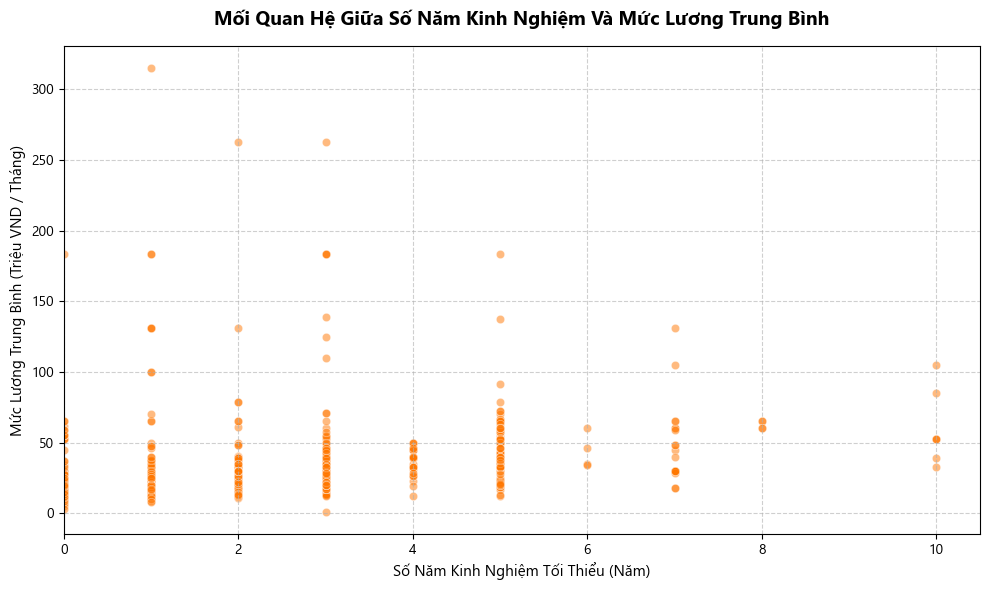

In [59]:
# 1. Cấu hình để vẽ biểu đồ hiển thị đúng font tiếng Việt không bị lỗi ô vuông
plt.rcParams['font.family'] = 'Segoe UI' # Hoặc 'Arial', 'Tahoma' tùy máy em
plt.figure(figsize=(10, 6))

# 2. Loại bỏ các dòng bị Null ở cả 2 cột để tránh lỗi đồ thị
df_plot = df.dropna(subset=['mean_salary', 'experience'])

# Mẹo quy đổi mức lương sang đơn vị "Triệu VND" cho trục tọa độ ngắn gọn, dễ nhìn
df_plot['mean_salary_million'] = df_plot['mean_salary'] / 1000000


# 3. Vẽ b
sns.scatterplot(
    data=df_plot, 
    x='experience', 
    y='mean_salary_million', 
    alpha=0.5, # Độ trong suốt để nhìn rõ những chỗ các chấm đè lên nhau
    color="#ff7700"
)


# 4. Trang trí biểu đồ chuẩn phong cách báo cáo khoa học
plt.title('Mối Quan Hệ Giữa Số Năm Kinh Nghiệm Và Mức Lương Trung Bình', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Số Năm Kinh Nghiệm Tối Thiểu (Năm)', fontsize=11)
plt.ylabel('Mức Lương Trung Bình (Triệu VND / Tháng)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6) # Thêm lưới mờ cho dễ dóng hàng

# Thới hạn hiển thị trục X gọn gàng từ 0 đến tối đa số năm kinh nghiệm thực tế trong data
plt.xlim(0, df_plot['experience'].max() + 0.5)

# 5. Hiển thị biểu đồ
plt.tight_layout()
plt.show()


C:\Users\HAN NGA\AppData\Local\Temp\ipykernel_10820\1035102999.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_plot['mean_salary_million'] = df_plot['mean_salary'] / 1000000


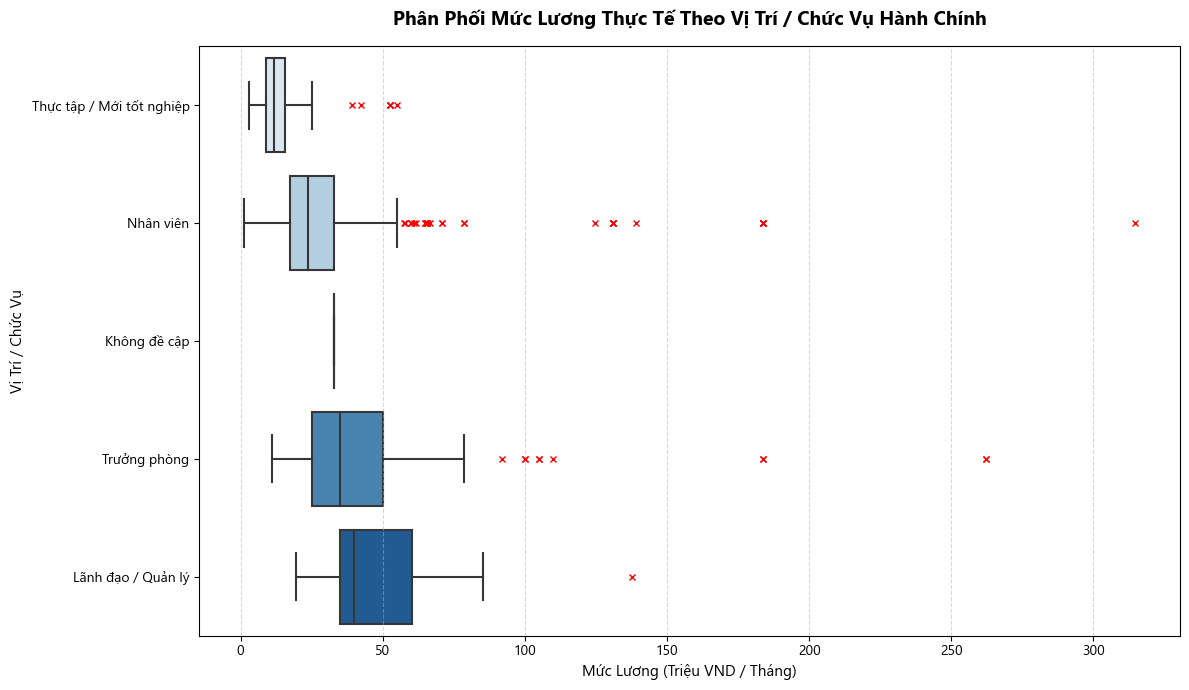

In [65]:
# LƯƠNG VÀ CHỨC VỊ

# 1. Cấu hình hiển thị đúng font tiếng Việt không bị lỗi ô vuông
plt.rcParams['font.family'] = 'Segoe UI'  # Hoặc 'Arial', 'Tahoma'
plt.figure(figsize=(12, 7))

# 2. Dọn dẹp dữ liệu trống (Null) trước khi vẽ
df_plot = df.dropna(subset=['mean_salary', 'job_position'])

# Quy đổi đơn vị lương sang "Triệu VND" cho trục tọa độ tinh tế, sạch sẽ
df_plot['mean_salary_million'] = df_plot['mean_salary'] / 1000000

# Tự động tính trung vị (Median) lương để sắp xếp thứ tự các chức vụ từ thấp đến cao
order_positions = df_plot.groupby('job_position')['mean_salary_million'].median().sort_values().index

# 3. Vẽ biểu đồ Boxplot ngang
# Thuộc tính flierprops dùng để làm đẹp các chấm lương đột biến (Outliers)
sns.boxplot(
    data=df_plot,
    x='mean_salary_million',
    y='job_position',
    order=order_positions,
    palette='Blues',  # Hệ màu xanh dương chuyển sắc theo cấp bậc nhân sự
    flierprops={"marker": "x", "markerfacecolor": "red", "markeredgecolor": "red", "markersize": 5} # Outliers màu đỏ gạch chéo
)

# 4. Trang trí biểu đồ chuẩn phong cách báo cáo khoa học xuất sắc
plt.title('Phân Phối Mức Lương Thực Tế Theo Vị Trí / Chức Vụ Hành Chính', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Mức Lương (Triệu VND / Tháng)', fontsize=11)
plt.ylabel('Vị Trí / Chức Vụ', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5)  # Lưới dọc mờ để dễ dóng hàng tiền

# 5. Hiển thị biểu đồ
plt.tight_layout()
plt.show()


In [3]:
# review file data
filename_3 = r"data_vnw_3.csv"

df=pd.read_csv(filename_3)
df.head(5)

,index,job_url,keyword,job_title,company,location,salary,date_posted,deadline_date,category,...,edu,test,co_hien_thi_luong,loai_tien_te,viet_tat_trieu,tinh_theo_nam,salary_min,salary_max,mean_salary_no_unit,mean_salary
0,1,https://www.vietnamworks.com/kiem-toan-vien-ki...,Data Analyst,Kiểm Toán Viên / Kiểm Toán Nội Bộ,Ngân Hàng Thương Mại TNHH MTV Ngoại Thương Côn...,Hà Nội,Thương lượng,27/03/2026,2026-04-26,Kiểm Toán,...,Đại học,Thương lượng,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,https://www.vietnamworks.com/ky-su-phat-trien-...,Data Analyst,"Kỹ Sư Phát Triển Nền Tảng, Hệ Thống","Viện Phát Triển Chuyển Đổi Xanh, Chuyển Đổi Số...",Hà Nội,Thương lượng,27/03/2026,2026-04-26,Data Engineer/Data Analyst/AI,...,Ko yêu cầu,Thương lượng,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,https://www.vietnamworks.com/chuyen-vien-cao-c...,Data Analyst,Chuyên Viên Cao Cấp Vận Hành Thương Hiệu Quốc Tế,Trang Văn hóa công ty,Hồ Chí Minh,Thương lượng,27/03/2026,2026-04-26,Tiếp Thị,...,Đại học,Thương lượng,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,https://www.vietnamworks.com/nhan-vien-phat-tr...,Data Analyst,Nhân Viên Phát Triển Dự Án Nông Nghiệp (Agricu...,CÔNG TY TNHH MUYUAN VIỆT NAM,Hồ Chí Minh,16tr-30tr ₫/tháng,27/03/2026,2026-04-26,Nông/Lâm/Ngư nghiệp,...,Cao đẳng,tr tr ₫/tháng,16tr-30tr ₫/tháng,vnd,triệu,tháng,16.0,30.0,23.0,23000000.0
4,5,https://www.vietnamworks.com/ie-engineer-20310...,Data Analyst,IE Engineer,CÔNG TY TNHH DỆT REGENT VIỆT NAM,Phú Thọ,Thương lượng,27/03/2026,2026-04-26,Thiết Kế Công Nghiệp/Kỹ Thuật,...,Đại học,Thương lượng,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Xóa cột phụ nếu không cần thiết nữa
df = df.drop(columns=['test', 'co_hien_thi_luong', 'loai_tien_te', 'viet_tat_trieu', 'tinh_theo_nam', 
                      'salary_min', 'salary_max', 'mean_salary_no_unit'])

In [7]:
## 2. SAVED lần 3
df.to_csv("data_vnw_3.csv", index=False, encoding="utf-8-sig")

## 2.7. date_posted DATE TIME

In [8]:
# 1. Chuyển đổi cột 'date_post' sang kiểu datetime (nếu chưa có)
df['date_posted'] = pd.to_datetime(df['date_posted'])
df['date_posted'].head(5)

C:\Users\HAN NGA\AppData\Local\Temp\ipykernel_10356\204210396.py:2: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['date_posted'] = pd.to_datetime(df['date_posted'])


0   2026-03-27
1   2026-03-27
2   2026-03-27
3   2026-03-27
4   2026-03-27
Name: date_posted, dtype: datetime64[ns]

In [ ]:
# Chuyển đổi trực tiếp 2 cột từ datetime sang chỉ lấy phần ngày (date)
df['date_posted'] = df['date_posted'].dt.date

In [12]:
df['date_posted'].value_counts().head(10)

date_posted
2026-03-25    47
2026-03-27    46
2026-03-13    45
2026-03-09    45
2026-03-30    45
2026-04-03    43
2026-04-16    42
2026-03-26    42
2026-04-17    42
2026-04-29    42
Name: count, dtype: int64

In [13]:
## 2. SAVED lần 4
df.to_csv("data_vnw_4.csv", index=False, encoding="utf-8-sig")